In [1]:
import json
from pathlib import Path

import cv2
import numpy as np
from IPython.display import Image, display

# Grid step in pixels. Layout 1 prints a 3 m x 3 m box that measures 99 px, so 1 m is 33 px.
# Layout 2 prints no scale, so its grid is only a visual guide of about one booth tile.
# Layout 3 prints a 2 m dimension over a 67 px booth, so 1 m is 33 px.
# Layouts 4, 5, 6 use 33 px as standard reference grid.
GRID_PX = {
    "../output/swift5/plan1": 33,
    "../output/swift5/plan2": 60,
    "../output/swift5/plan3": 33,
    "../output/swift5/plan4": 33,
    "../output/swift5/plan5": 33,
    "../output/swift5/plan6": 33,
}

# BGR colour and line width for the classes swift finds outside the legend; -1 fills the box.
OUTSIDE = {
    "wall": ((0, 0, 0), 3),
    "door": ((0, 160, 0), 4),
    "pillar": ((90, 90, 90), -1),
    "object": ((0, 140, 255), 2),
}


In [2]:
def render(out_dir, suggested=False, width=1000):
    p = Path(out_dir)
    layout = json.loads((p / "layout.json").read_text())
    print(f"=== {p.name} Report ===")
    print(json.dumps(layout["report"], indent=2))

    W, H = layout["image"]["width"], layout["image"]["height"]
    step = GRID_PX.get(str(out_dir), GRID_PX.get(p.name, 60 if "2" in str(out_dir) else 33))
    canvas = np.full((H, W, 3), 255, np.uint8)
    for i, pos in enumerate(range(0, max(W, H), step)):
        shade = (170, 170, 170) if i % 5 == 0 else (225, 225, 225)
        cv2.line(canvas, (pos, 0), (pos, H), shade, 1)
        cv2.line(canvas, (0, pos), (W, pos), shade, 1)

    for it in layout["items"]:
        x, y, w, h = it["box"]
        cls = it.get("class", "")
        if cls in OUTSIDE:
            color, line_width = OUTSIDE[cls]
            if it.get("polygon") and len(it["polygon"]) >= 3:
                pts = [np.array(it["polygon"], np.int32)]
                if line_width < 0:
                    cv2.fillPoly(canvas, pts, color)
                else:
                    cv2.polylines(canvas, pts, True, color, line_width)
            else:
                cv2.rectangle(canvas, (x, y), (x + w, y + h), color, line_width)
            continue

        fill = it.get("fill_rgb", [180, 180, 180])
        outline = tuple(fill[::-1])
        if min(outline) > 235:  # near-white legend rows would vanish on the white canvas
            outline = (160, 160, 160)
        if it.get("polygon") and len(it["polygon"]) >= 3:  # sloped booths keep their slanted edges
            cv2.polylines(canvas, [np.array(it["polygon"], np.int32)], True, outline, 3)
        else:
            cv2.rectangle(canvas, (x, y), (x + w, y + h), outline, 3)

        text = it.get("id")
        color = (0, 0, 0)
        if suggested and it.get("suggested_id"):
            text = it["suggested_id"]
            color = (220, 100, 30)  # blue in BGR
        elif text is None:
            if it.get("suggested_id"):
                text = it["suggested_id"]
                color = (220, 100, 30)  # blue in BGR
            else:
                text = "?"
                color = (30, 30, 220)  # red in BGR

        if text:
            scale = max(0.4, min(0.7, h / 40.0))
            cv2.putText(canvas, text, (x + 4, y + h // 2 + 5), cv2.FONT_HERSHEY_SIMPLEX, scale, color, 2)

    render_path = p / "render.png"
    cv2.imwrite(str(render_path), canvas)
    display(Image(data=cv2.imencode(".png", canvas)[1].tobytes(), width=width))


=== plan1 Report ===
{
  "duplicate_ids": [
    "D6"
  ],
  "gaps_in_numbering": {
    "C": [
      6
    ]
  },
  "ids_read": 154,
  "items_per_class": {
    "Blocked": 3,
    "Booth A": 9,
    "Booth B": 26,
    "Booth C": 21,
    "Booth D": 8,
    "Booth F": 27,
    "Booth G": 25,
    "Booth H": 18,
    "Booth J": 5,
    "Booth K": 10,
    "Entrance": 13,
    "Large booth X": 3,
    "Large booth XX": 3,
    "Stage": 2,
    "door": 11,
    "object": 895,
    "pillar": 23,
    "wall": 35
  },
  "items_without_id": 983,
  "max_number_per_prefix": {
    "A": 9,
    "B": 26,
    "C": 21,
    "D": 8,
    "F": 27,
    "G": 25,
    "H": 18,
    "J": 4,
    "K": 10,
    "X": 3,
    "XX": 3
  }
}


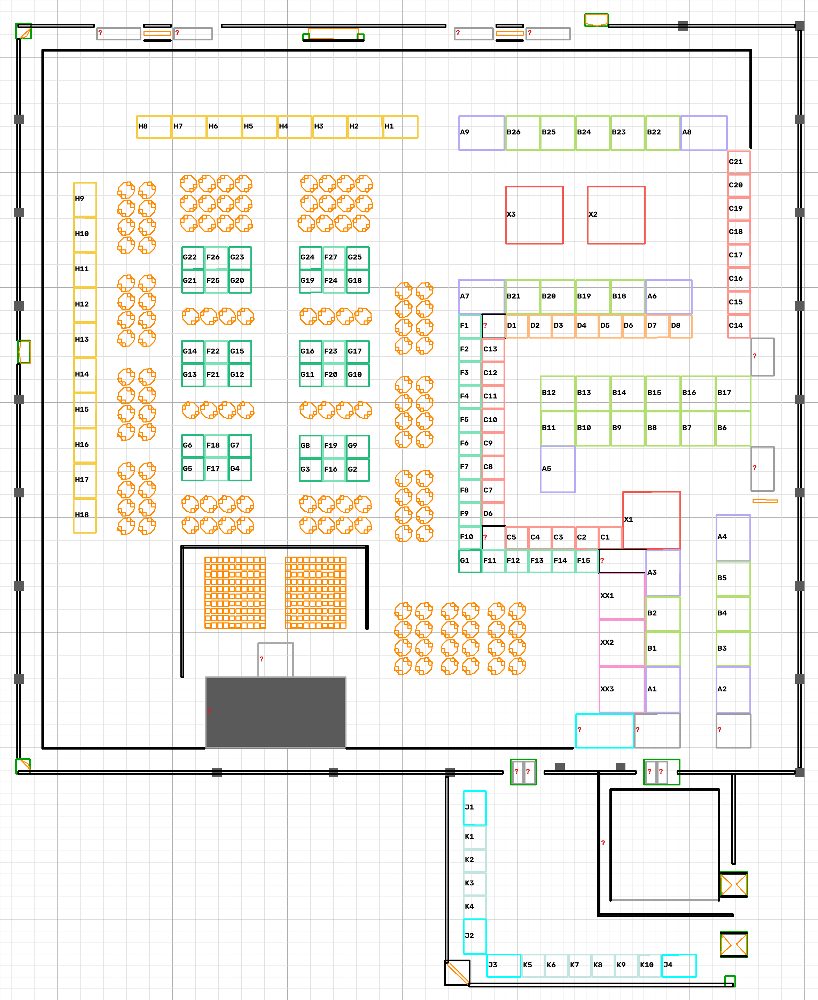

In [3]:
render("../output/swift5/plan1")  # Plan 1: 154 booths


=== plan2 Report ===
{
  "duplicate_ids": [],
  "gaps_in_numbering": {
    "F": [
      1
    ]
  },
  "ids_read": 208,
  "items_per_class": {
    "Booth A": 112,
    "Booth B": 30,
    "Booth C": 16,
    "Booth F": 42,
    "Interactive space I": 9,
    "Unlabeled block": 2,
    "door": 4,
    "object": 148,
    "pillar": 1,
    "wall": 21
  },
  "items_without_id": 177,
  "max_number_per_prefix": {
    "A": 112,
    "B": 30,
    "C": 16,
    "F": 42,
    "I": 9
  }
}


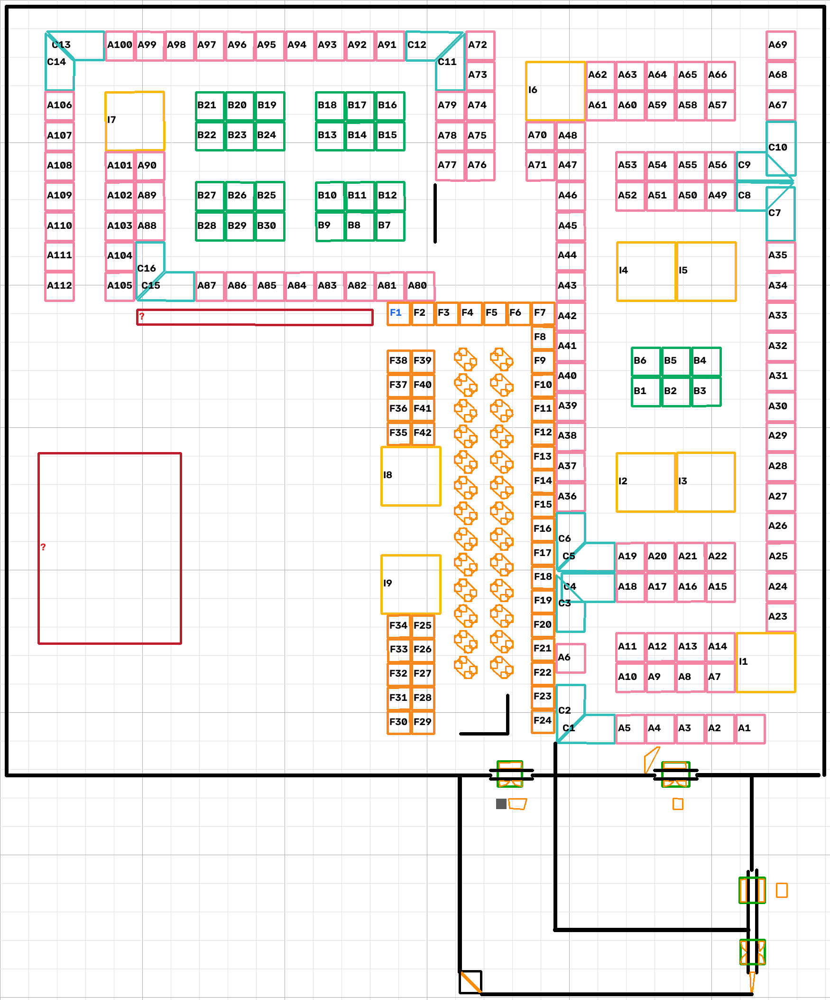

In [4]:
render("../output/swift5/plan2")  # Plan 2: 208 booths


=== plan3 Report ===
{
  "duplicate_ids": [],
  "gaps_in_numbering": {
    "H": [
      4,
      13,
      14,
      24,
      34,
      40,
      41,
      42,
      43,
      44,
      45,
      46,
      47,
      48,
      49,
      54,
      64,
      74,
      84
    ]
  },
  "ids_read": 67,
  "items_per_class": {
    "Booth H": 67,
    "Stage": 1,
    "Tenant space": 6,
    "door": 1,
    "object": 56,
    "pillar": 32,
    "wall": 37
  },
  "items_without_id": 133,
  "max_number_per_prefix": {
    "H": 86
  }
}


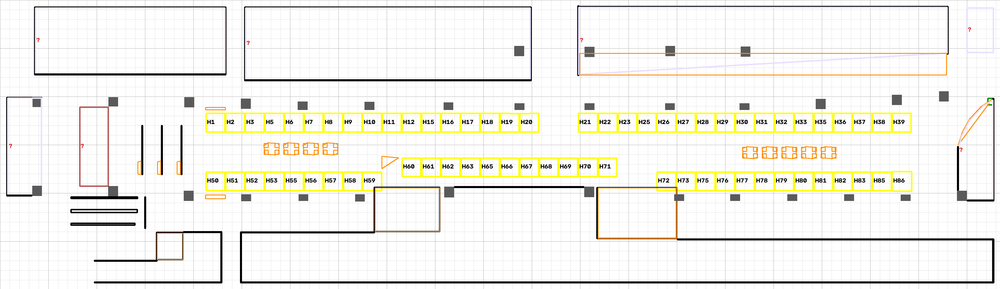

In [5]:
render("../output/swift5/plan3")  # Plan 3: 67 booths


=== plan4 Report ===
{
  "duplicate_ids": [
    "N8"
  ],
  "gaps_in_numbering": {
    "CD": [
      1,
      2,
      3,
      4,
      5,
      7,
      8,
      9,
      10,
      11,
      12,
      13,
      14,
      15,
      16,
      17,
      18,
      19,
      20,
      21,
      22,
      23,
      24,
      25,
      26,
      27,
      29,
      30,
      31,
      32,
      33,
      34,
      35,
      36,
      37,
      38,
      40,
      41,
      42,
      43,
      44,
      45,
      46,
      47,
      48,
      49,
      50
    ],
    "CO": [
      1,
      2,
      3,
      4,
      5,
      6,
      7,
      8,
      9,
      10,
      11,
      12,
      13,
      14,
      15,
      16,
      17,
      18,
      19,
      20,
      21,
      22,
      23,
      24,
      25
    ],
    "FNB": [
      3,
      5,
      7,
      8,
      10,
      12,
      13,
      14,
      15,
      16,
      17
    ],
    "FNE": [
      1,
      2,
      4,
      5,
    

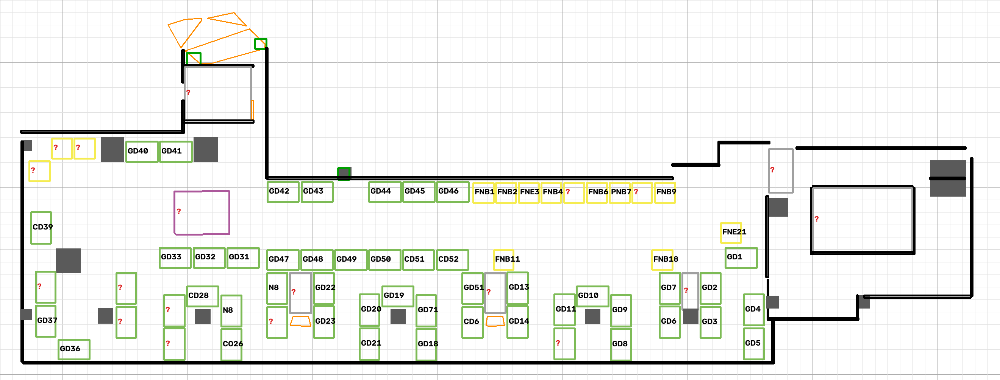

In [6]:
render("../output/swift5/plan4")  # Plan 4: 55 booths


=== plan5 Report ===
{
  "duplicate_ids": [],
  "gaps_in_numbering": {
    "A": [
      1,
      2,
      4,
      5,
      6,
      7,
      8,
      9,
      10
    ],
    "B": [
      1,
      2,
      3,
      4,
      5,
      6,
      11,
      12,
      13,
      14,
      15,
      16,
      19,
      21,
      26,
      28
    ],
    "C": [
      1,
      2,
      3,
      4,
      5,
      6,
      12,
      13,
      14,
      15,
      16,
      18,
      19,
      21
    ],
    "D": [
      1,
      2,
      3,
      4,
      5,
      6,
      8,
      9,
      10,
      11,
      12,
      14,
      15,
      16,
      18,
      21,
      23,
      26,
      29
    ],
    "E": [
      1,
      2,
      3,
      4,
      5,
      6,
      9,
      10,
      11,
      12,
      14,
      15,
      16
    ],
    "F": [
      1,
      2,
      4,
      5,
      6,
      10,
      13
    ],
    "G": [
      1,
      4,
      6,
      7,
      9,
      10,
      11,
      12,
 

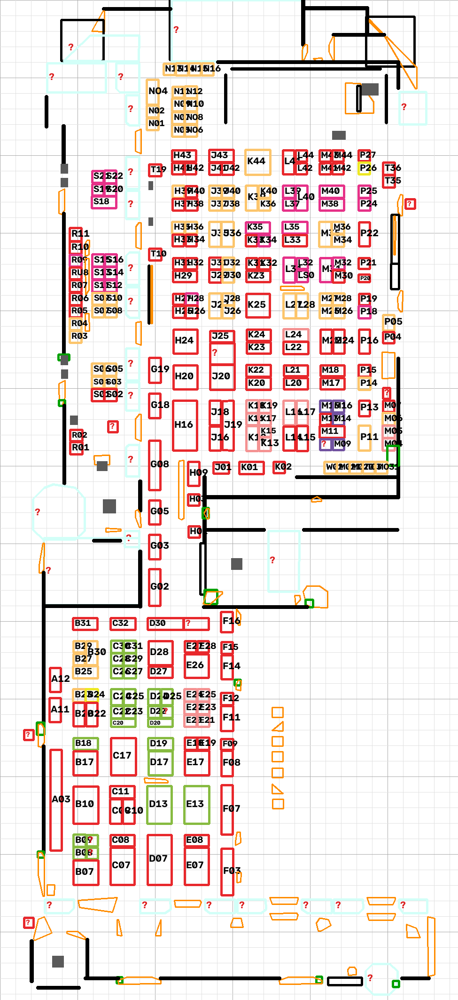

In [7]:
render("../output/swift5/plan5")  # Plan 5: 270 booths


=== plan6 Report ===
{
  "duplicate_ids": [
    "B38",
    "B39"
  ],
  "gaps_in_numbering": {
    "B": [
      4
    ],
    "M": [
      3,
      38,
      39
    ],
    "\u042d\u041b": [
      1,
      2,
      3,
      4,
      5,
      6
    ]
  },
  "ids_read": 282,
  "items_per_class": {
    "Booth B": 77,
    "Booth F": 88,
    "Booth M": 57,
    "Booth S": 15,
    "Booth W": 34,
    "FACILITIES": 23,
    "GRID NETWORK": 4,
    "SPONSOR BOOTH": 18,
    "STAGE AREA": 2,
    "door": 35,
    "object": 99,
    "pillar": 53,
    "wall": 115
  },
  "items_without_id": 338,
  "max_number_per_prefix": {
    "B": 81,
    "F": 90,
    "M": 61,
    "S": 15,
    "W": 36,
    "\u042d\u041b": 7
  }
}


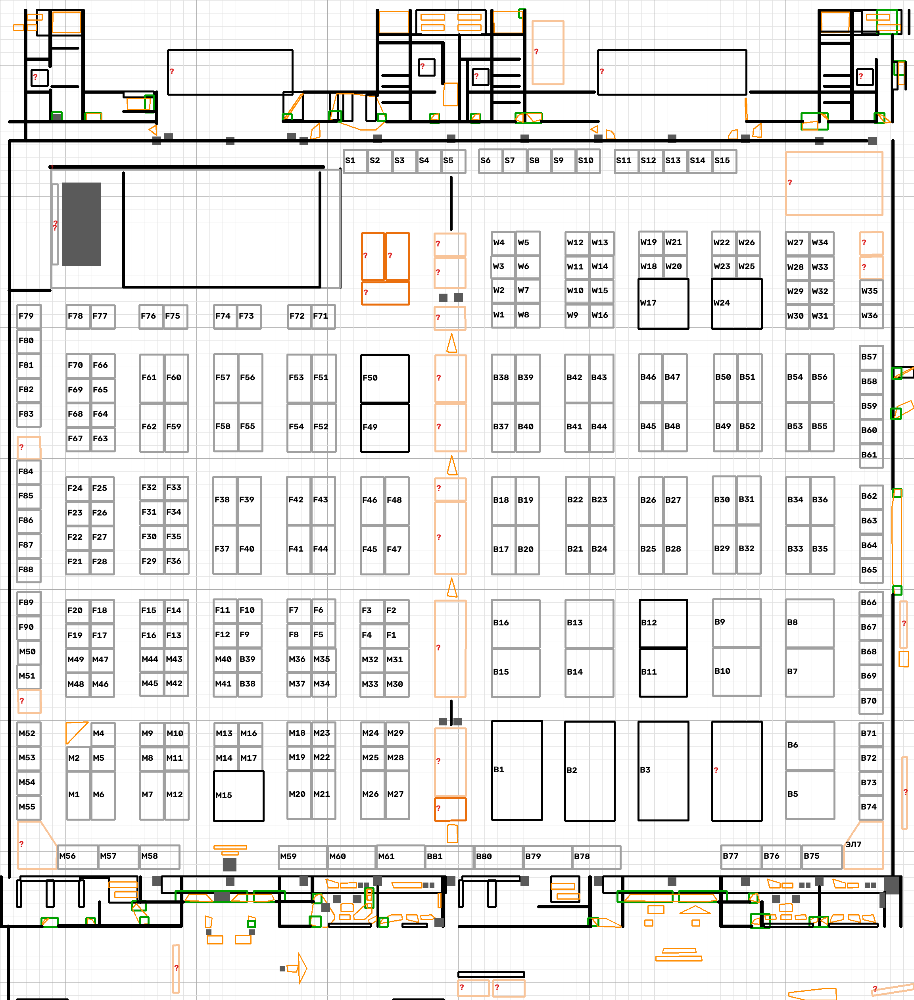

In [8]:
render("../output/swift5/plan6")  # Plan 6: 282 booths


Saved ../output/swift5/plan1/side_by_side.png


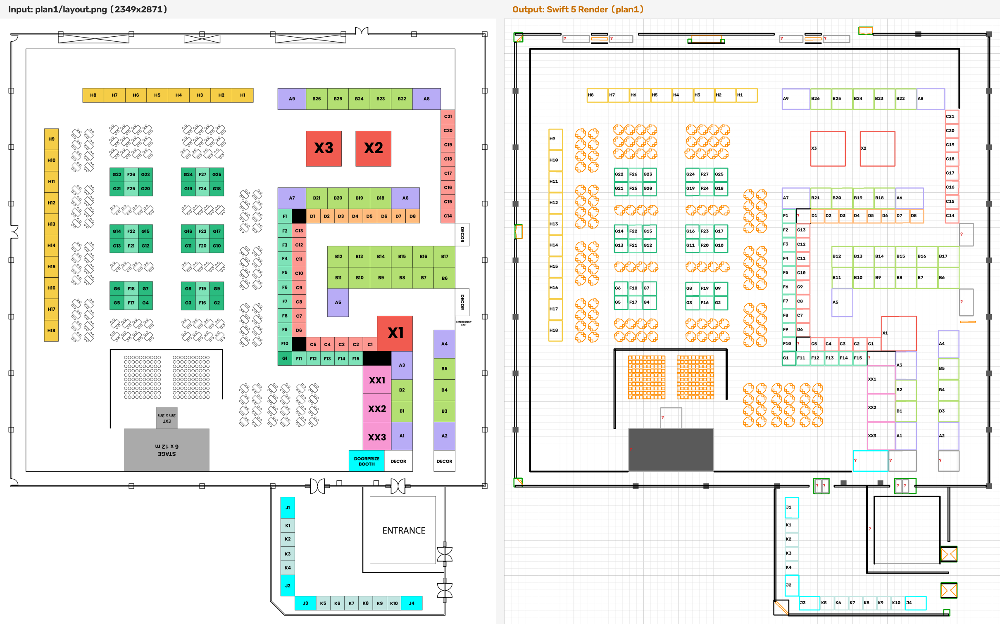

Saved ../output/swift5/plan2/side_by_side.png


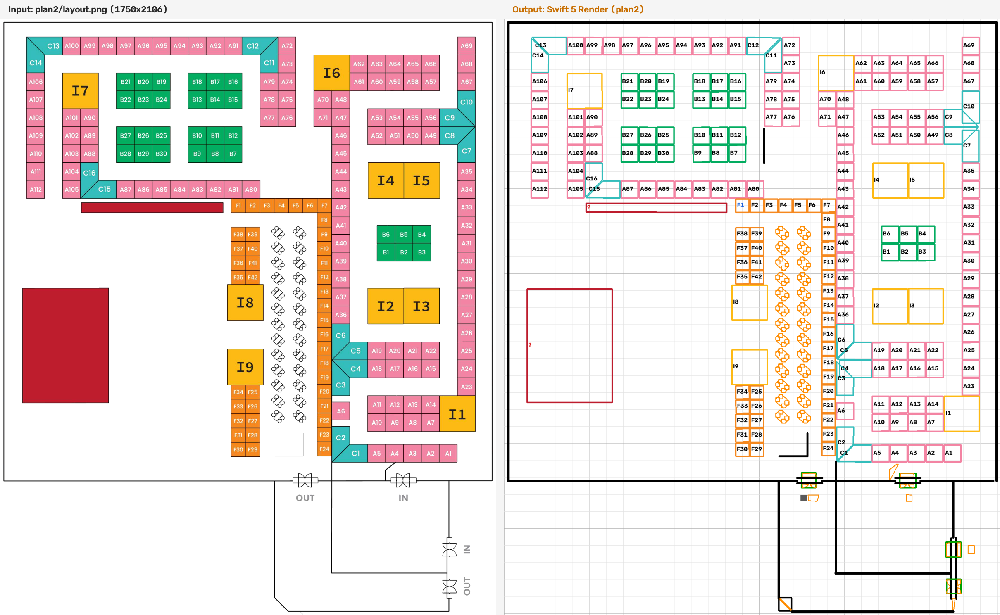

Saved ../output/swift5/plan3/side_by_side.png


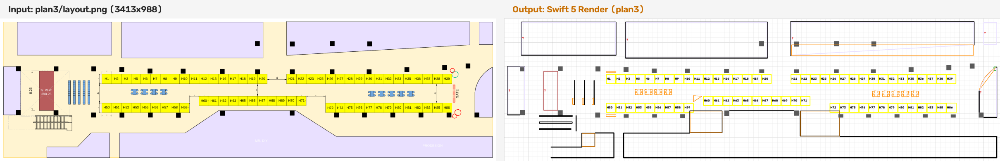

Saved ../output/swift5/plan4/side_by_side.png


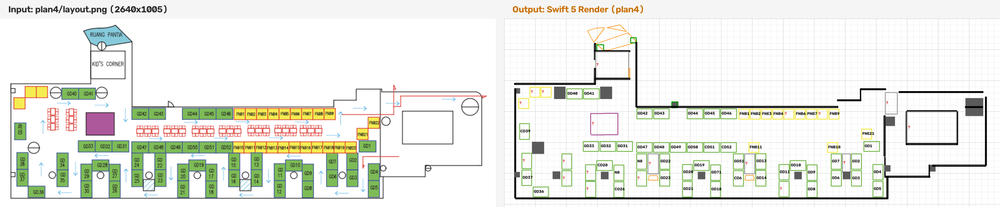

Saved ../output/swift5/plan5/side_by_side.png


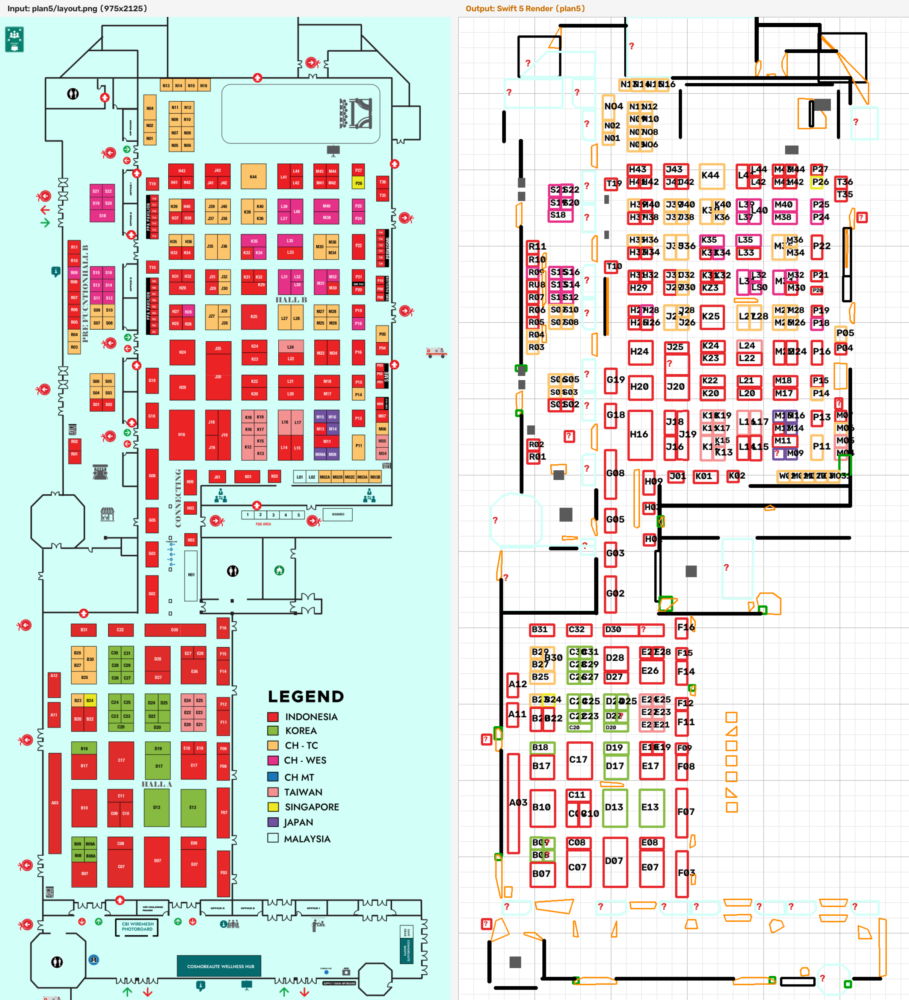

Saved ../output/swift5/plan6/side_by_side.png


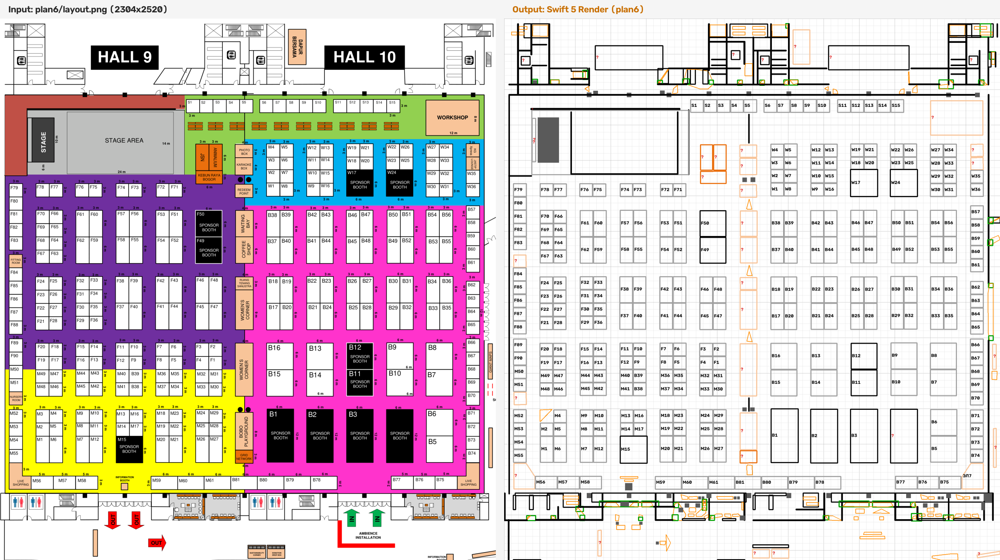


Saved multi-page PDF: ../output/swift5/side_by_side.pdf (6 pages)


[PosixPath('../output/swift5/plan1/side_by_side.png'),
 PosixPath('../output/swift5/plan2/side_by_side.png'),
 PosixPath('../output/swift5/plan3/side_by_side.png'),
 PosixPath('../output/swift5/plan4/side_by_side.png'),
 PosixPath('../output/swift5/plan5/side_by_side.png'),
 PosixPath('../output/swift5/plan6/side_by_side.png')]

In [9]:
# Save input + output side-by-side for all plans and export as multi-page PDF
from PIL import Image as PILImage

def save_side_by_side_all(root_dir="..", target_w=1200):
    root = Path(root_dir) if (Path(root_dir) / "data").exists() else Path(".")
    plans = [f"plan{i}" for i in range(1, 7)]
    saved_pngs = []
    pdf_images = []

    for pname in plans:
        inp_path = root / f"data/{pname}/layout.png"
        out_dir = root / f"output/swift5/{pname}"
        rend_path = out_dir / "render.png"

        if not inp_path.exists() or not rend_path.exists():
            continue

        orig = cv2.imread(str(inp_path))
        rend = cv2.imread(str(rend_path))
        H, W = orig.shape[:2]

        s = target_w / W
        target_h = int(round(H * s))
        r_orig = cv2.resize(orig, (target_w, target_h), interpolation=cv2.INTER_AREA)
        r_rend = cv2.resize(rend, (target_w, target_h), interpolation=cv2.INTER_AREA)

        bar_h = 45
        combo = np.full((target_h + bar_h, target_w * 2 + 20, 3), 245, dtype=np.uint8)
        combo[bar_h : bar_h + target_h, 0:target_w] = r_orig
        combo[bar_h : bar_h + target_h, target_w + 20 : target_w * 2 + 20] = r_rend

        cv2.putText(combo, f"Input: {pname}/layout.png ({W}x{H})", (20, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.75, (40, 40, 40), 2)
        cv2.putText(combo, f"Output: Swift 5 Render ({pname})", (target_w + 40, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.75, (0, 110, 200), 2)

        sbs_path = out_dir / "side_by_side.png"
        cv2.imwrite(str(sbs_path), combo)
        saved_pngs.append(sbs_path)
        pdf_images.append(PILImage.open(sbs_path).convert("RGB"))
        print(f"Saved {sbs_path}")
        display(Image(data=cv2.imencode(".png", combo)[1].tobytes(), width=1000))

    if pdf_images:
        pdf_out = root / "output/swift5/side_by_side.pdf"
        pdf_images[0].save(pdf_out, save_all=True, append_images=pdf_images[1:], resolution=150)
        print(f"\nSaved multi-page PDF: {pdf_out} ({len(pdf_images)} pages)")

    return saved_pngs

save_side_by_side_all()
